### Загрузка датасета и просмотр первых записей

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/shopease_raw_orders.csv")
df.head()

,OrderID,CustomerID,OrderDate,CustomerAge,Gender,City,Category,Product,Quantity,UnitPrice,Discount,PaymentMethod,OrderStatus,DeliveryDate,Rating,TotalAmount
0,18129,C0507,2026-02-01 23:39:00,68.0,Female,Alexandria,Electronics,Laptop,4,18000,0.0,Wallet,Delivered,2026-02-04 23:39:00,5.0,72000.0
1,11666,C0207,2026-03-03 10:37:00,21.0,Female,Cairo,Sports,Yoga Mat,2,600,0.1,Wallet,Delivered,2026-03-07 10:37:00,1.0,1080.0
2,12859,C1112,2026-05-23 17:57:00,23.0,Male,Aswan,Fashion,Shoes,-1,1500,10%,Bank Transfer,Delivered,2026-05-27 17:57:00,4.0,1350.0
3,19787,C1322,2026-01-29 07:51:00,23.0,Male,Tanta,Beauty,Hair Dryer,4,1300,0.1,Wallet,Delivered,2026-01-30 07:51:00,4.0,4680.0
4,16473,C0314,2026-06-23 20:17:00,62.0,Female,Tanta,Electronics,Laptop,1,18000,0.1,Mastercard,Delivered,2026-06-27 20:17:00,5.0,16200.0


### Проверка пропусков и уникальности OrderID

In [27]:
ORDER_ID_COL = "OrderID"

missing_count = df[ORDER_ID_COL].isna().sum()
print(f"{ORDER_ID_COL}: пропусков {missing_count} ({missing_count / len(df):.1%})")
print(f"Уникальных значений: {df[ORDER_ID_COL].nunique(dropna=True)}")
print(f"Дубликатов среди непустых ID: {df[ORDER_ID_COL].dropna().duplicated().sum()}")

OrderID: пропусков 0 (0.0%)
Уникальных значений: 10000
Дубликатов среди непустых ID: 20


### Проверка пропусков и числа клиентов CustomerID

In [28]:
CUSTOMER_ID_COL = "CustomerID"

missing_count = df[CUSTOMER_ID_COL].isna().sum()
print(f"{CUSTOMER_ID_COL}: пропусков {missing_count} ({missing_count / len(df):.1%})")
print(f"Уникальных клиентов: {df[CUSTOMER_ID_COL].nunique(dropna=True)}")

CustomerID: пропусков 15 (0.1%)
Уникальных клиентов: 1988


### Проверка пропусков в OrderDate и DeliveryDate

In [25]:
DATE_COLS = ["OrderDate", "DeliveryDate"]

for col in DATE_COLS:
    missing_count = df[col].isna().sum()
    print(f"{col}: пропусков {missing_count} ({missing_count / len(df):.1%})")

OrderDate: пропусков 0 (0.0%)
DeliveryDate: пропусков 2230 (22.3%)


### Проверка корректности дат заказа и доставки

In [26]:
for col in DATE_COLS:
    parsed_dates = pd.to_datetime(df[col], errors="coerce")
    invalid_mask = df[col].notna() & parsed_dates.isna()
    print(f"{col}: некорректных значений {invalid_mask.sum()}")

order_dates = pd.to_datetime(df["OrderDate"], errors="coerce")
delivery_dates = pd.to_datetime(df["DeliveryDate"], errors="coerce")
invalid_sequence = order_dates.notna() & delivery_dates.notna() & (delivery_dates < order_dates)
print(f"DeliveryDate раньше OrderDate: {invalid_sequence.sum()}")
print("Диапазон OrderDate:", order_dates.min(), "—", order_dates.max())
print("Диапазон DeliveryDate:", delivery_dates.min(), "—", delivery_dates.max())

OrderDate: некорректных значений 523
DeliveryDate: некорректных значений 0
DeliveryDate раньше OrderDate: 23
Диапазон OrderDate: 2026-01-01 00:02:00 — 2026-06-29 23:40:00
Диапазон DeliveryDate: 2025-12-29 14:21:00 — 2026-07-06 18:21:00


### Анализ распределения заказов по полу

count      10020
unique        10
top       Female
freq        4839
Name: Gender, dtype: object

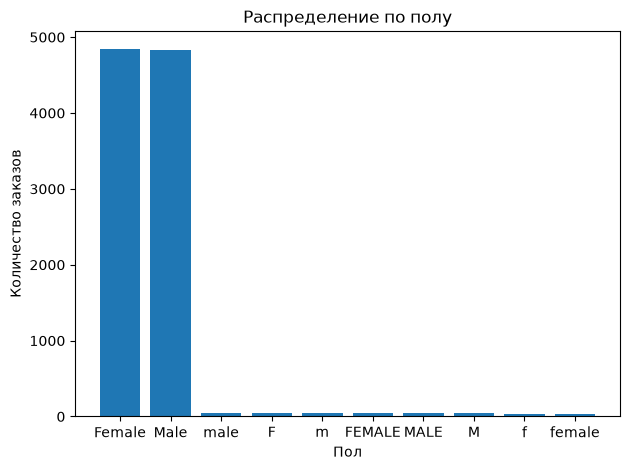

In [14]:
GENDER_COL = "Gender"

display(df[GENDER_COL].describe())

gender_counts = df[GENDER_COL].fillna("Пропуск").value_counts()

plt.bar(gender_counts.index.map(str), gender_counts.values)
plt.title("Распределение по полу")
plt.xlabel("Пол")
plt.ylabel("Количество заказов")
plt.tight_layout()
plt.show()

### Сводная статистика по городам

count     10020
unique       30
top       Cairo
freq       3620
Name: City, dtype: object

Пропущенных значений: 0


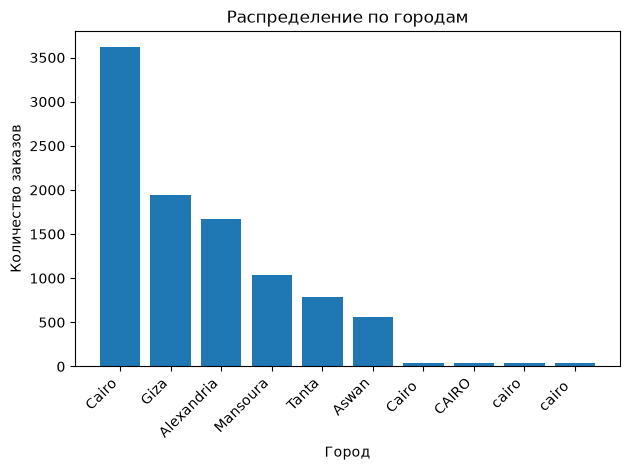

In [34]:
CITY_COL = "City"

display(df[CITY_COL].describe())

city_counts = df[CITY_COL].fillna("Пропуск").value_counts().head(10)

print(f"Пропущенных значений: {df[CITY_COL].isna().sum()}")

plt.bar(city_counts.index.map(str), city_counts.values)
plt.title("Распределение по городам")
plt.xlabel("Город")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Анализ десяти наиболее частых категорий товаров

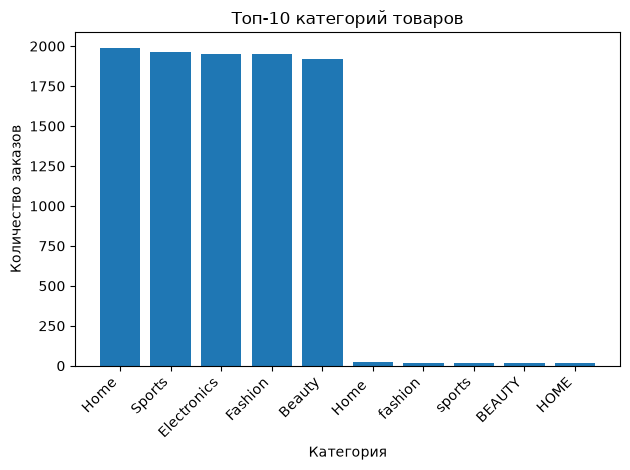

In [16]:
CATEGORY_COL = "Category"

category_counts = df[CATEGORY_COL].fillna("Пропуск").value_counts().head(10)

plt.bar(category_counts.index.map(str), category_counts.values)
plt.title("Топ-10 категорий товаров")
plt.xlabel("Категория")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Сводная статистика по товарам

In [36]:
PRODUCT_COL = "Product"

display(df[PRODUCT_COL].describe())

print(f"Пропущенных значений: {df[PRODUCT_COL].isna().sum()}")

count            10000
unique              90
top       Coffee Maker
freq               440
Name: Product, dtype: object

Пропущенных значений: 20


### Анализ распределения способов оплаты

count     9970
unique      20
top       Cash
freq      2012
Name: PaymentMethod, dtype: object

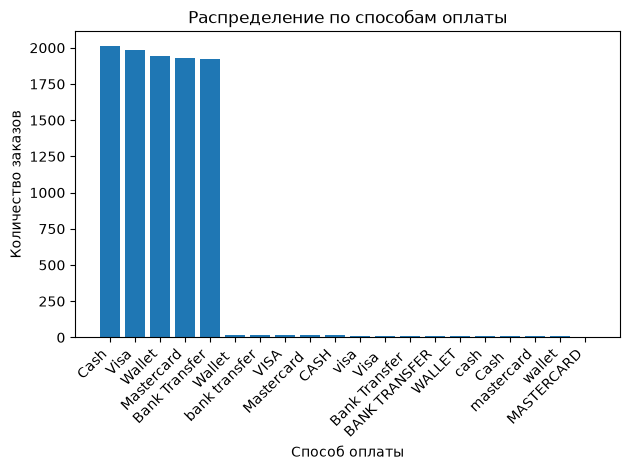

In [22]:
PAYMENT_METHOD_COL = "PaymentMethod"

display(df[PAYMENT_METHOD_COL].describe())

payment_method_counts = df[PAYMENT_METHOD_COL].fillna("Пропуск").value_counts()

plt.bar(payment_method_counts.index.map(str), payment_method_counts.values)
plt.title("Распределение по способам оплаты")
plt.xlabel("Способ оплаты")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Анализ распределения статусов заказа

count         10020
unique           13
top       Delivered
freq           7636
Name: OrderStatus, dtype: object

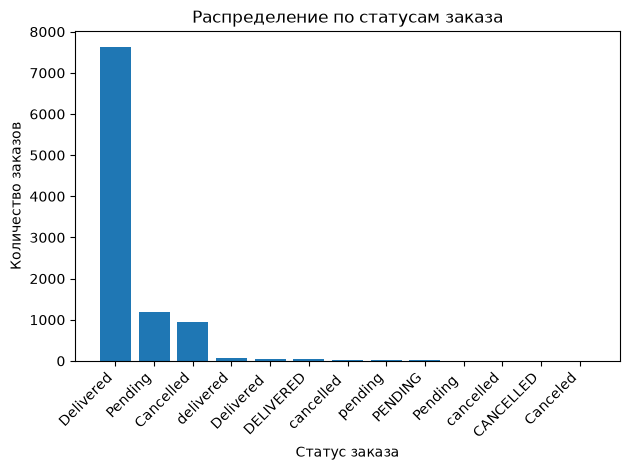

In [37]:
ORDER_STATUS_COL = "OrderStatus"

display(df[ORDER_STATUS_COL].describe())

order_status_col_counts = df[ORDER_STATUS_COL].fillna("Пропуск").value_counts()

plt.bar(order_status_col_counts.index.map(str), order_status_col_counts.values)
plt.title("Распределение по статусам заказа")
plt.xlabel("Статус заказа")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()